# Fichas de perfil y mapa nacional (clases latentes)

Visualizaciones de la segmentacion final: las 6 clases latentes del notebook 08 como perfiles,
los subperfiles del notebook 09 y la escolaridad por seccion del notebook 10 (ECEG 2020).

Salidas en `DATA/PREPROCESSED/fichas/`:
- Vista general de los 6 perfiles.
- Una ficha por perfil (PNG de alta resolucion) y todas juntas en un PDF.
- Mapa estatico del perfil dominante por municipio.
- Mapa interactivo (HTML) con capas estatal y municipal.

El cruce de municipios con el shapefile se hace **por nombre**, no por clave: las claves
municipales del INE no coinciden con las del INEGI (solo ~1,085 de 2,477 coinciden en clave y
nombre). El mapa del notebook 04 cruza por clave, por lo que muchos municipios muestran datos de
otro municipio.

## 1. Configuracion

In [1]:
import difflib
import re
import unicodedata
import warnings
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "white"})

## 2. Parametros y rutas

`NOMBRES` son los nombres definitivos de los perfiles (elegidos por el equipo). Si es `None` se usan
los descriptores automaticos de la seccion 4.2 como nombre.

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"
DIR_GEO = ROOT / "DATA" / "RAW" / "marco_geoestadistico"
DIR_FICHAS = DIR_PREPROCESSED / "fichas"
DIR_FICHAS.mkdir(exist_ok=True)

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
ANOS = [2009, 2012, 2015, 2018, 2021, 2024]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
REGIONES_ORDEN = ["Noroeste", "Noreste", "Occidente", "Centro", "Sur-Sureste"]
LLAVES = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
CORTES_ESC = [0, 8, 10, 12, 30]
TRAMOS_ESC = ["<8", "8-10", "10-12", "12+"]

NOMBRES = {
    0: "Por convencer",
    1: "Constancia que se apaga",
    2: "Generación en ascenso",
    3: "Paso firme",
    4: "Voces que avanzan",
    5: "Pilar democrático",
}
COLORES_PERFIL = ["#c0392b", "#e67e22", "#d4a017", "#5dade2", "#2e86c1", "#1e8449"]
COLOR_SIN_DATOS = "#d9d9d9"

UMBRAL_CLARA = 0.8
MIN_PERSONAS_ENTIDAD = 20_000
MIN_PERSONAS_MPIO = 1_000
TOL_MUNICIPIO = 0.01
TOL_ESTADO = 0.02
DPI_FICHA = 200

EDONOM = {
    1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur",
    4: "Campeche", 5: "Coahuila", 6: "Colima", 7: "Chiapas", 8: "Chihuahua",
    9: "Ciudad de Mexico", 10: "Durango", 11: "Guanajuato", 12: "Guerrero",
    13: "Hidalgo", 14: "Jalisco", 15: "Mexico", 16: "Michoacan", 17: "Morelos",
    18: "Nayarit", 19: "Nuevo Leon", 20: "Oaxaca", 21: "Puebla", 22: "Queretaro",
    23: "Quintana Roo", 24: "San Luis Potosi", 25: "Sinaloa", 26: "Sonora",
    27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala", 30: "Veracruz",
    31: "Yucatan", 32: "Zacatecas",
}

### 2.1 Funciones auxiliares

In [3]:
def media_ponderada(df, col, por):
    grupos = [df[c] for c in por]
    wx = (df[col] * df["peso"]).groupby(grupos).sum()
    return wx / df["peso"].where(df[col].notna()).groupby(grupos).sum()


def dominante(df, por, col):
    t = df.groupby(por + [col])["peso"].sum()
    return t.groupby(level=por).idxmax().map(lambda x: x[-1])


def resumen(df, por):
    personas = df.groupby(por)["peso"].sum()
    out = pd.DataFrame({"personas": personas, "pct_pob": personas / df["peso"].sum() * 100})
    pct = ["MUJER", "RURAL_MIXTA", "CLARA", "MENOR_40"]
    for col in ["promedio", "brecha_pres", "tendencia", "P_PJ2025", "escolaridad", "pct_posbasica", "pct_internet"] + pct:
        out[col] = media_ponderada(df, col, por)
    out[pct] *= 100
    out["edad_dominante"] = dominante(df, por, "GRUPO_EDAD")
    return out


def sobrerrepresentacion(df, grupo, dim, min_personas):
    t = df.groupby([grupo, dim])["peso"].sum().rename("personas").reset_index()
    t["pct_en_categoria"] = t["personas"] / t.groupby(dim)["personas"].transform("sum") * 100
    pct_nacional = df.groupby(grupo)["peso"].sum() / df["peso"].sum() * 100
    t["indice"] = t["pct_en_categoria"] / t[grupo].map(pct_nacional) * 100
    t = t[t["personas"] >= min_personas]
    return t.sort_values([grupo, "indice"], ascending=[True, False]).reset_index(drop=True)

## 3. Carga de datos

### 3.1 Celdas

Celdas del notebook 03 con peso = SV + NV de 2024 y municipio. Se conservan las celdas sin tasa
PJ 2025 (Campeche no tiene datos de la eleccion judicial); los promedios PJ usan solo celdas con dato.

Escolaridad e internet del notebook 10: cada celda toma el grado promedio de escolaridad y el % con
educacion posbasica de su seccion para su sexo, y el % de viviendas con internet de su seccion (dato
de la seccion, no individual).

In [4]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV", "MPIOCVE", "MPIONOM"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(LLAVES, observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
sec_mpio = (
    fed24.groupby(["EDOCVE", "SECCION"])
    .agg(MPIOCVE=("MPIOCVE", "first"), MPIONOM=("MPIONOM", "first"))
    .reset_index()
)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=LLAVES, how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .merge(sec_mpio, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso"])
    .reset_index(drop=True)
)
del pesos, secciones, sec_mpio

eceg = pd.read_parquet(DIR_PREPROCESSED / "secciones_eceg_2020.parquet")
celdas = celdas.merge(eceg, on=["EDOCVE", "SECCION"], how="left")
mujer, hombre = celdas["SEXO"] == 1, celdas["SEXO"] == 0
celdas["escolaridad"] = np.select([mujer, hombre], [celdas["GRAPROES_F"], celdas["GRAPROES_M"]], celdas["GRAPROES"])
celdas["pct_posbasica"] = np.select([mujer, hombre], [celdas["PCT_POSBASICA_F"], celdas["PCT_POSBASICA_M"]], celdas["PCT_POSBASICA"])
celdas["pct_internet"] = celdas["PCT_INTERNET"]
celdas["tramo_esc"] = pd.cut(celdas["escolaridad"], CORTES_ESC, labels=TRAMOS_ESC, right=False).astype(str)
celdas = celdas.drop(columns=eceg.columns.drop(["EDOCVE", "SECCION"]))
del eceg

celdas["MUJER"] = (celdas["SEXO"] == 1).astype(float)
celdas["RURAL_MIXTA"] = (celdas["TIPOSEC"].astype(str) != "U").astype(float)
celdas["MENOR_40"] = celdas["GRUPO_EDAD"].isin(ETIQUETAS_EDAD[:3]).astype(float)
celdas["entidad"] = celdas["EDOCVE"].map(EDONOM)
print(f"Celdas: {len(celdas):,}  peso: {celdas['peso'].sum():,.0f}")
print(f"Personas sin escolaridad: {celdas.loc[celdas['escolaridad'].isna(), 'peso'].sum():,.0f}")

Celdas: 657,497  peso: 71,203,577
Personas sin escolaridad: 10,279


### 3.2 Perfiles y subperfiles

Clases latentes del notebook 08 (renumeradas por promedio de participacion) y subperfiles del 09.
El 09 debe haberse ejecutado con `ORIGEN_PERFILES = "clases_latentes"`.

In [5]:
lca = pd.read_parquet(DIR_PREPROCESSED / "celdas_clases_latentes.parquet", columns=LLAVES + ["clase", "prob_clase"])
sub = pd.read_parquet(DIR_PREPROCESSED / "celdas_subperfiles.parquet", columns=LLAVES + ["subperfil"])
celdas = celdas.merge(lca, on=LLAVES, how="left").merge(sub, on=LLAVES, how="left")
assert celdas[["clase", "subperfil"]].notna().all().all()

orden = media_ponderada(celdas, "promedio", ["clase"]).sort_values().index
celdas["perfil"] = celdas["clase"].map({old: new for new, old in enumerate(orden)}).astype(int)
assert (celdas["subperfil"].str.split(".").str[0].astype(int) == celdas["perfil"]).all(), \
    "Los subperfiles no corresponden a las clases latentes: ejecutar el 09 con ORIGEN_PERFILES = 'clases_latentes'"
celdas["CLARA"] = (celdas["prob_clase"] >= UMBRAL_CLARA).astype(float)

K = celdas["perfil"].nunique()
print(f"Perfiles: {K}  subperfiles: {celdas['subperfil'].nunique()}")

Perfiles: 6  subperfiles: 27


## 4. Resumen y nombres

### 4.1 Resumen ponderado

Por perfil y por subperfil, mas las referencias nacionales (trayectoria, edad, region y escolaridad).

In [6]:
res_perfil = resumen(celdas, ["perfil"])
res_sub = resumen(celdas, ["perfil", "subperfil"])
tray_perfil = pd.DataFrame({e: media_ponderada(celdas, e, ["perfil"]) for e in ELECCIONES})

w_total = celdas["peso"].sum()
nac_tray = [np.average(celdas[e], weights=celdas["peso"]) for e in ELECCIONES]
nac_edad = celdas.groupby("GRUPO_EDAD")["peso"].sum()[ETIQUETAS_EDAD] / w_total * 100
nac_reg = celdas.groupby("REGION")["peso"].sum()[REGIONES_ORDEN] / w_total * 100
con_esc = celdas[celdas["escolaridad"].notna()]
nac_esc_tramo = con_esc.groupby("tramo_esc")["peso"].sum()[TRAMOS_ESC] / con_esc["peso"].sum() * 100
nac_esc = np.average(con_esc["escolaridad"], weights=con_esc["peso"])
con_int = celdas[celdas["pct_internet"].notna()]
nac_internet = np.average(con_int["pct_internet"], weights=con_int["peso"])

ent_perfil = sobrerrepresentacion(celdas, "perfil", "entidad", MIN_PERSONAS_ENTIDAD)
ent_sub = sobrerrepresentacion(celdas, "subperfil", "entidad", MIN_PERSONAS_ENTIDAD)
res_perfil.round(1)

,personas,pct_pob,promedio,brecha_pres,tendencia,P_PJ2025,escolaridad,pct_posbasica,pct_internet,MUJER,RURAL_MIXTA,CLARA,MENOR_40,edad_dominante
perfil,,,,,,,,,,,,,,
0,15253119,21.4,37.3,14.3,1.1,11.1,9.3,41.0,50.6,25.4,26.7,92.3,87.2,30-39
1,5934456,8.3,48.5,7.6,-1.6,10.0,9.1,38.2,49.3,43.5,36.2,44.3,62.6,30-39
2,13265429,18.6,50.5,18.4,3.0,14.0,10.0,48.6,54.6,52.6,23.7,59.1,66.4,30-39
3,11639641,16.3,60.3,9.3,-0.1,11.9,9.6,43.6,51.8,56.7,32.5,56.9,33.6,40-49
4,8413205,11.8,62.0,19.5,4.5,15.2,10.1,49.9,53.3,68.2,27.3,51.3,31.3,40-49
5,16697727,23.5,72.8,10.6,1.8,15.0,9.8,46.2,49.1,68.9,37.6,81.8,14.8,50-59


### 4.2 Descriptores automaticos

Nivel por promedio (<45 baja, <55 media, <65 media-alta, resto alta) y rasgos por forma:
brecha >= 17 "se moviliza en presidenciales", brecha <= 10 "estable entre elecciones",
tendencia >= 2.5 "en ascenso", tendencia <= -1 "en descenso". Se usan como subtitulo de cada perfil,
debajo del nombre definitivo de `NOMBRES`.

In [7]:
def nombre_auto(r):
    if r["promedio"] < 45:
        partes = ["Baja participacion"]
    elif r["promedio"] < 55:
        partes = ["Participacion media"]
    elif r["promedio"] < 65:
        partes = ["Participacion media-alta"]
    else:
        partes = ["Alta participacion"]
    if r["brecha_pres"] >= 17:
        partes.append("se moviliza en presidenciales")
    elif r["brecha_pres"] <= 10:
        partes.append("estable entre elecciones")
    if r["tendencia"] >= 2.5:
        partes.append("en ascenso")
    elif r["tendencia"] <= -1:
        partes.append("en descenso")
    return ", ".join(partes)


DESCRIPTORES = {p: nombre_auto(r) for p, r in res_perfil.iterrows()}
if NOMBRES is None:
    NOMBRES = DESCRIPTORES
for p in NOMBRES:
    print(f"Perfil {p}: {NOMBRES[p]}  ({DESCRIPTORES[p]})")

Perfil 0: Por convencer  (Baja participacion)
Perfil 1: Constancia que se apaga  (Participacion media, estable entre elecciones, en descenso)
Perfil 2: Generación en ascenso  (Participacion media, se moviliza en presidenciales, en ascenso)
Perfil 3: Paso firme  (Participacion media-alta, estable entre elecciones)
Perfil 4: Voces que avanzan  (Participacion media-alta, se moviliza en presidenciales, en ascenso)
Perfil 5: Pilar democrático  (Alta participacion)


## 5. Vista general

Trayectorias de los 6 perfiles frente al promedio nacional y mapa de perfiles (nivel contra brecha
presidencial, tamano proporcional a personas). Pensada para el documento y la presentacion.

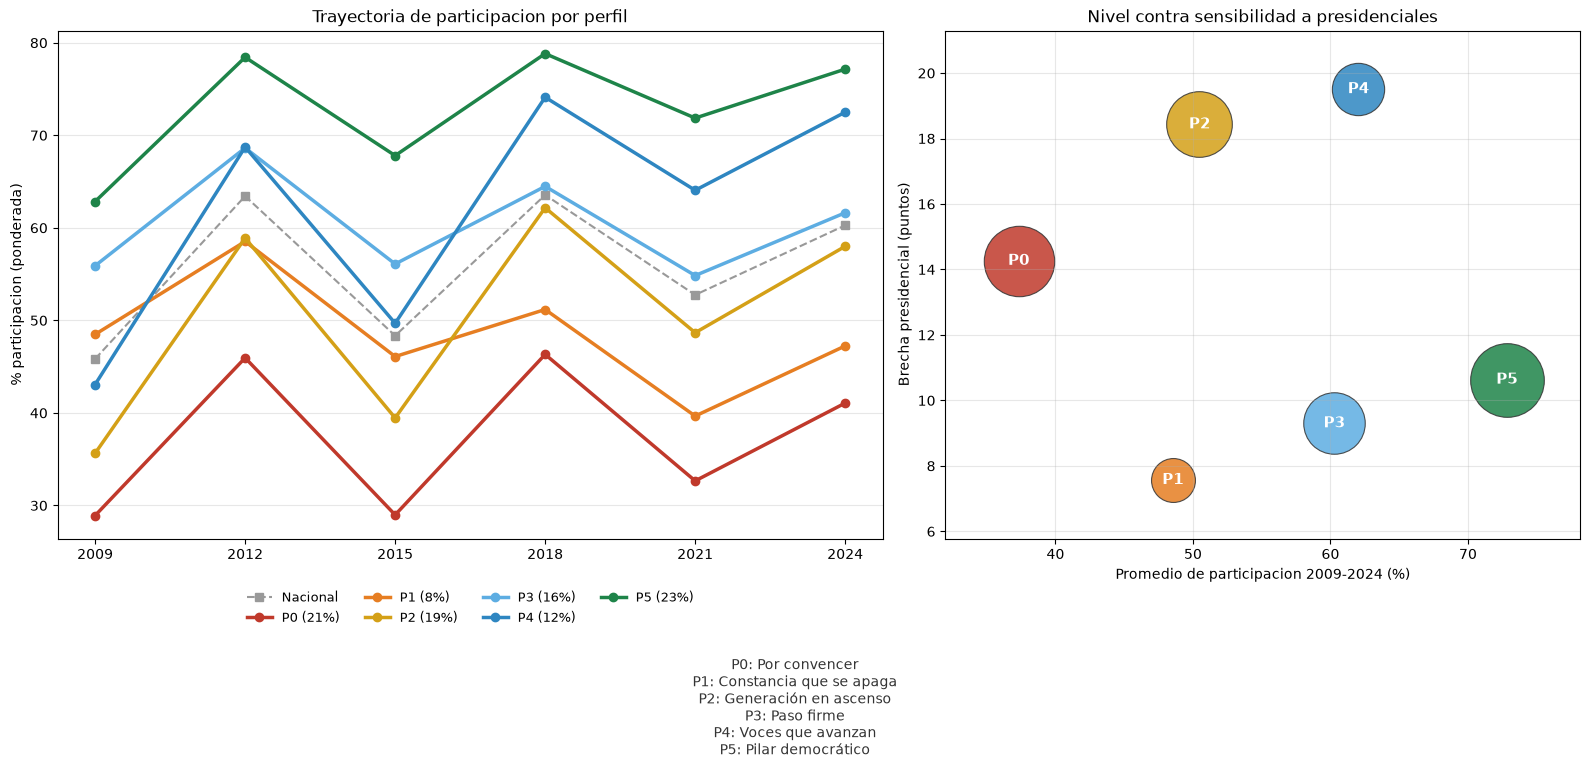

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

ax1.plot(ANOS, nac_tray, "s--", color="#999", linewidth=1.5, label="Nacional")
for p in range(K):
    ax1.plot(ANOS, tray_perfil.loc[p].to_numpy(), "o-", color=COLORES_PERFIL[p], linewidth=2.5,
             label=f"P{p} ({res_perfil.loc[p, 'pct_pob']:.0f}%)")
ax1.set_xticks(ANOS)
ax1.set_ylabel("% participacion (ponderada)")
ax1.set_title("Trayectoria de participacion por perfil")
ax1.grid(axis="y", alpha=0.3)
ax1.legend(fontsize=9, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)

for p, r in res_perfil.iterrows():
    ax2.scatter(r["promedio"], r["brecha_pres"], s=r["pct_pob"] * 120, color=COLORES_PERFIL[p],
                alpha=0.85, edgecolor="#333", linewidth=0.8)
    ax2.annotate(f"P{p}", (r["promedio"], r["brecha_pres"]), ha="center", va="center",
                 fontsize=11, fontweight="bold", color="white")
ax2.set_xlabel("Promedio de participacion 2009-2024 (%)")
ax2.set_ylabel("Brecha presidencial (puntos)")
ax2.set_title("Nivel contra sensibilidad a presidenciales")
ax2.grid(alpha=0.3)
ax2.margins(0.15)

leyenda = "\n".join(f"P{p}: {NOMBRES[p]}" for p in range(K))
fig.text(0.5, -0.02, leyenda, ha="center", va="top", fontsize=10, color="#333")
plt.tight_layout()
fig.savefig(DIR_FICHAS / "vista_general.png", dpi=DPI_FICHA, bbox_inches="tight")
plt.show()

## 6. Geometrias y cruce de municipios

### 6.1 Geometrias

Shapefile municipal 2022 de CONABIO/INEGI, simplificado para que el mapa sea ligero.

In [9]:
gdf_mun = pyogrio.read_dataframe(DIR_GEO / "mun22gw.shp", encoding="latin-1")
gdf_mun["EDOCVE"] = gdf_mun["CVE_ENT"].astype(int)
gdf_mun["geometry"] = gdf_mun.geometry.simplify(TOL_MUNICIPIO, preserve_topology=True)

gdf_edo = gdf_mun.dissolve(by="EDOCVE").reset_index()[["EDOCVE", "NOM_ENT", "geometry"]]
gdf_edo["geometry"] = gdf_edo.geometry.simplify(TOL_ESTADO, preserve_topology=True)
print(f"Municipios: {len(gdf_mun):,}  entidades: {len(gdf_edo)}")

Municipios: 2,475  entidades: 32


### 6.2 Cruce por nombre

Los nombres se normalizan (sin acentos ni signos, mayusculas, abreviaturas Gral. y Dr. expandidas)
y se cruzan dentro de cada entidad en tres pasos:

1. **exacto:** mismo nombre normalizado (solo nombres sin duplicado en la entidad).
2. **contenido:** un nombre contiene al otro (ej. "Jonacatepec" en "Jonacatepec de Leandro Valle").
3. **aproximado:** el nombre libre mas parecido (`difflib`, similitud >= 0.6).

Quedan sin cruce los nombres duplicados o ambiguos dentro de una entidad (ej. "San Pedro Mixtepec",
contenido en dos municipios de Oaxaca) y los municipios creados despues de 2022.

In [10]:
ABREVIATURAS = {"GRAL": "GENERAL", "DR": "DOCTOR"}


def normalizar(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()
    return " ".join(ABREVIATURAS.get(p, p) for p in re.sub(r"[^A-Z0-9 ]", " ", s).split())


mun_ine = celdas.groupby(["EDOCVE", "MPIOCVE", "MPIONOM"], as_index=False)["peso"].sum()
mun_ine["nom"] = mun_ine["MPIONOM"].map(normalizar)
geo = gdf_mun[["EDOCVE", "CVEGEO", "NOMGEO"]].assign(nom=gdf_mun["NOMGEO"].map(normalizar))

geo_unicos = geo.drop_duplicates(["EDOCVE", "nom"], keep=False)
ine_unico = ~mun_ine.duplicated(["EDOCVE", "nom"], keep=False).to_numpy()
cruce = mun_ine.merge(geo_unicos[["EDOCVE", "nom", "CVEGEO"]], on=["EDOCVE", "nom"], how="left")
cruce.loc[~ine_unico, "CVEGEO"] = np.nan
cruce["metodo"] = np.where(cruce["CVEGEO"].notna(), "exacto", "sin cruce")

for i in cruce.index[cruce["CVEGEO"].isna() & ine_unico]:
    e, nom = cruce.at[i, "EDOCVE"], cruce.at[i, "nom"]
    libres = geo_unicos[(geo_unicos["EDOCVE"] == e) & ~geo_unicos["CVEGEO"].isin(cruce["CVEGEO"].dropna())]
    contiene = libres[libres["nom"].map(lambda x: nom in x or x in nom)]
    if len(contiene) == 1:
        cruce.at[i, "CVEGEO"], cruce.at[i, "metodo"] = contiene["CVEGEO"].iloc[0], "contenido"
        continue
    if len(contiene) > 1:
        continue
    cand = difflib.get_close_matches(nom, libres["nom"].tolist(), n=1, cutoff=0.6)
    if cand:
        cruce.at[i, "CVEGEO"] = libres.loc[libres["nom"] == cand[0], "CVEGEO"].iloc[0]
        cruce.at[i, "metodo"] = "aproximado"

cruce = cruce.merge(geo[["CVEGEO", "NOMGEO"]], on="CVEGEO", how="left")
print(cruce["metodo"].value_counts().to_string())
print(f"Personas en municipios sin cruce: {cruce.loc[cruce['metodo'] == 'sin cruce', 'peso'].sum():,.0f}")

metodo
exacto        2354
contenido       10
aproximado       7
sin cruce        5
Personas en municipios sin cruce: 54,695


### 6.3 Revision de cruces no exactos

Lista completa para revisar a ojo los cruces por contenido o aproximados.

In [11]:
cruce.loc[cruce["metodo"] != "exacto", ["EDOCVE", "MPIONOM", "NOMGEO", "metodo"]].sort_values("metodo")

,EDOCVE,MPIONOM,NOMGEO,metodo
28,4,Hopelche}én,Hopelchén,aproximado
42,5,Cuatrociénegas,Cuatro Ciénegas,aproximado
119,7,Huitiupaán,Huitiupán,aproximado
182,7,Villacomaltitlán,Villa Comaltitlán,aproximado
494,13,San Agustón Metzquititlán,San Agustín Metzquititlán,aproximado
1980,29,Zitlaltépec de Trinidad Sánchez Santos,Ziltlaltépec de Trinidad Sánchez Santos,aproximado
2013,30,Alto Lucero de Gutiérrez Barios,Alto Lucero de Gutiérrez Barrios,aproximado
99,7,Cintalapa,Cintalapa de Figueroa,contenido
283,10,Simón Bolívar,General Simón Bolívar,contenido
900,17,Jonacatepec,Jonacatepec de Leandro Valle,contenido


### 6.4 Perfil dominante por municipio y entidad

Porcentaje de personas de cada perfil en cada municipio, perfil y subperfil dominantes. Los
municipios con menos de 1,000 personas se muestran sin datos.

In [12]:
claves = cruce[["EDOCVE", "MPIOCVE", "CVEGEO"]].drop_duplicates(["EDOCVE", "MPIOCVE"])
celdas = celdas.merge(claves, on=["EDOCVE", "MPIOCVE"], how="left")
geo_celdas = celdas.dropna(subset=["CVEGEO"])

dist_mun = geo_celdas.groupby(["CVEGEO", "perfil"])["peso"].sum().unstack(fill_value=0)
personas_mun = dist_mun.sum(axis=1)
pct_mun = dist_mun.div(personas_mun, axis=0) * 100
sub_dom = (
    geo_celdas.groupby(["CVEGEO", "subperfil"])["peso"].sum().reset_index()
    .sort_values("peso").drop_duplicates("CVEGEO", keep="last").set_index("CVEGEO")
)

mun = pd.DataFrame({
    "personas": personas_mun,
    "promedio": media_ponderada(geo_celdas, "promedio", ["CVEGEO"]),
    "escolaridad": media_ponderada(geo_celdas, "escolaridad", ["CVEGEO"]),
    "pct_internet": media_ponderada(geo_celdas, "pct_internet", ["CVEGEO"]),
    "perfil_dom": pct_mun.idxmax(axis=1),
    "pct_dom": pct_mun.max(axis=1),
    "subperfil_dom": sub_dom["subperfil"],
    "pct_subperfil_dom": sub_dom["peso"] / personas_mun * 100,
})
mun["suficiente"] = mun["personas"] >= MIN_PERSONAS_MPIO
mun = mun.join(pct_mun.add_prefix("pct_"))

gmun = gdf_mun.merge(mun, left_on="CVEGEO", right_index=True, how="left")
gmun["suficiente"] = gmun["suficiente"].eq(True)

dist_edo = celdas.groupby(["EDOCVE", "perfil"])["peso"].sum().unstack(fill_value=0)
edo = pd.DataFrame({
    "personas": dist_edo.sum(axis=1),
    "promedio": media_ponderada(celdas, "promedio", ["EDOCVE"]),
    "escolaridad": media_ponderada(celdas, "escolaridad", ["EDOCVE"]),
    "pct_internet": media_ponderada(celdas, "pct_internet", ["EDOCVE"]),
    "perfil_dom": dist_edo.idxmax(axis=1),
}).join((dist_edo.div(dist_edo.sum(axis=1), axis=0) * 100).add_prefix("pct_"))
gedo = gdf_edo.merge(edo, left_on="EDOCVE", right_index=True, how="left")

print(f"Municipios con datos suficientes: {gmun['suficiente'].sum():,} de {len(gmun):,}")
gmun.loc[gmun["suficiente"], "perfil_dom"].astype(int).value_counts().sort_index().rename("municipios")

Municipios con datos suficientes: 2,171 de 2,475


perfil_dom
0    346
1     38
2    315
3    215
4    307
5    950
Name: municipios, dtype: int64

## 7. Mapa estatico

Perfil dominante por municipio; en gris, municipios sin datos suficientes o sin cruce.

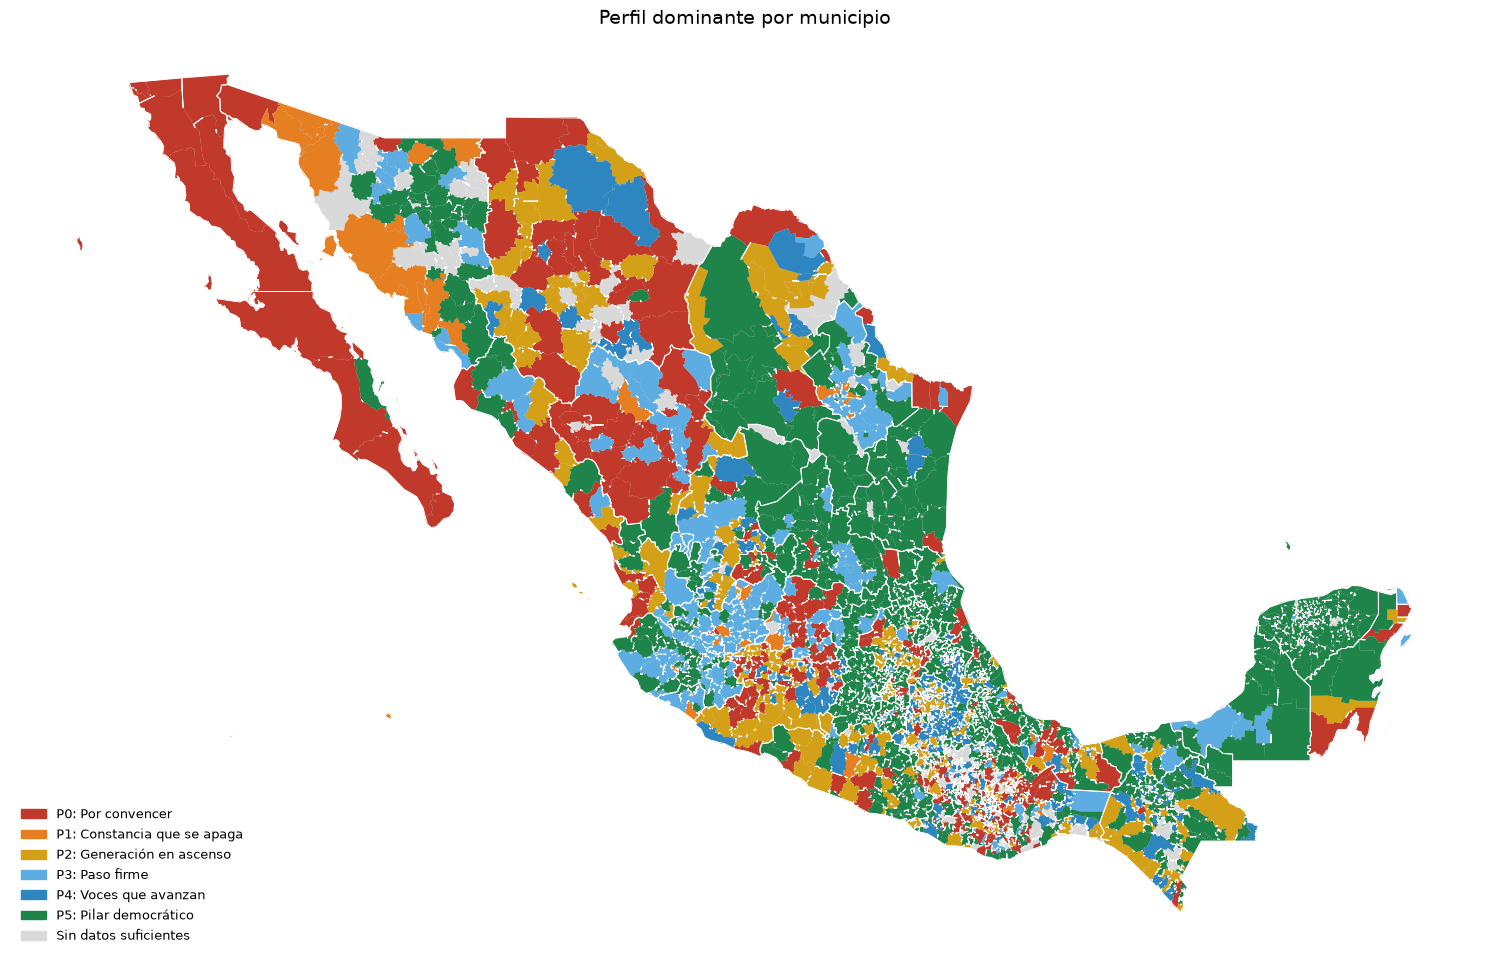

In [13]:
fig, ax = plt.subplots(figsize=(15, 10))
gmun.plot(ax=ax, color=COLOR_SIN_DATOS, linewidth=0)
for p in range(K):
    sel = gmun[gmun["suficiente"] & (gmun["perfil_dom"] == p)]
    sel.plot(ax=ax, color=COLORES_PERFIL[p], linewidth=0)
gdf_edo.boundary.plot(ax=ax, color="white", linewidth=0.7)
ax.legend(
    handles=[Patch(color=COLORES_PERFIL[p], label=f"P{p}: {NOMBRES[p]}") for p in range(K)]
    + [Patch(color=COLOR_SIN_DATOS, label="Sin datos suficientes")],
    loc="lower left", fontsize=9, frameon=False,
)
ax.set_title("Perfil dominante por municipio", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
fig.savefig(DIR_FICHAS / "mapa_perfil_dominante.png", dpi=DPI_FICHA, bbox_inches="tight")
plt.show()

## 8. Fichas de perfil

Una pagina por perfil:
- Trayectoria frente al promedio nacional y metricas clave.
- Edad, region y escolaridad de la seccion frente a la distribucion nacional (gris).
- Entidades donde esta sobrerrepresentado (indice 100 = promedio nacional).
- Mapa de presencia: % de la poblacion de cada municipio que pertenece al perfil.
- Subperfiles con sus rasgos (incluida escolaridad) y las 2 entidades donde mas se concentran.

Se guardan como PNG (200 dpi) y juntas en `fichas_perfiles.pdf`.

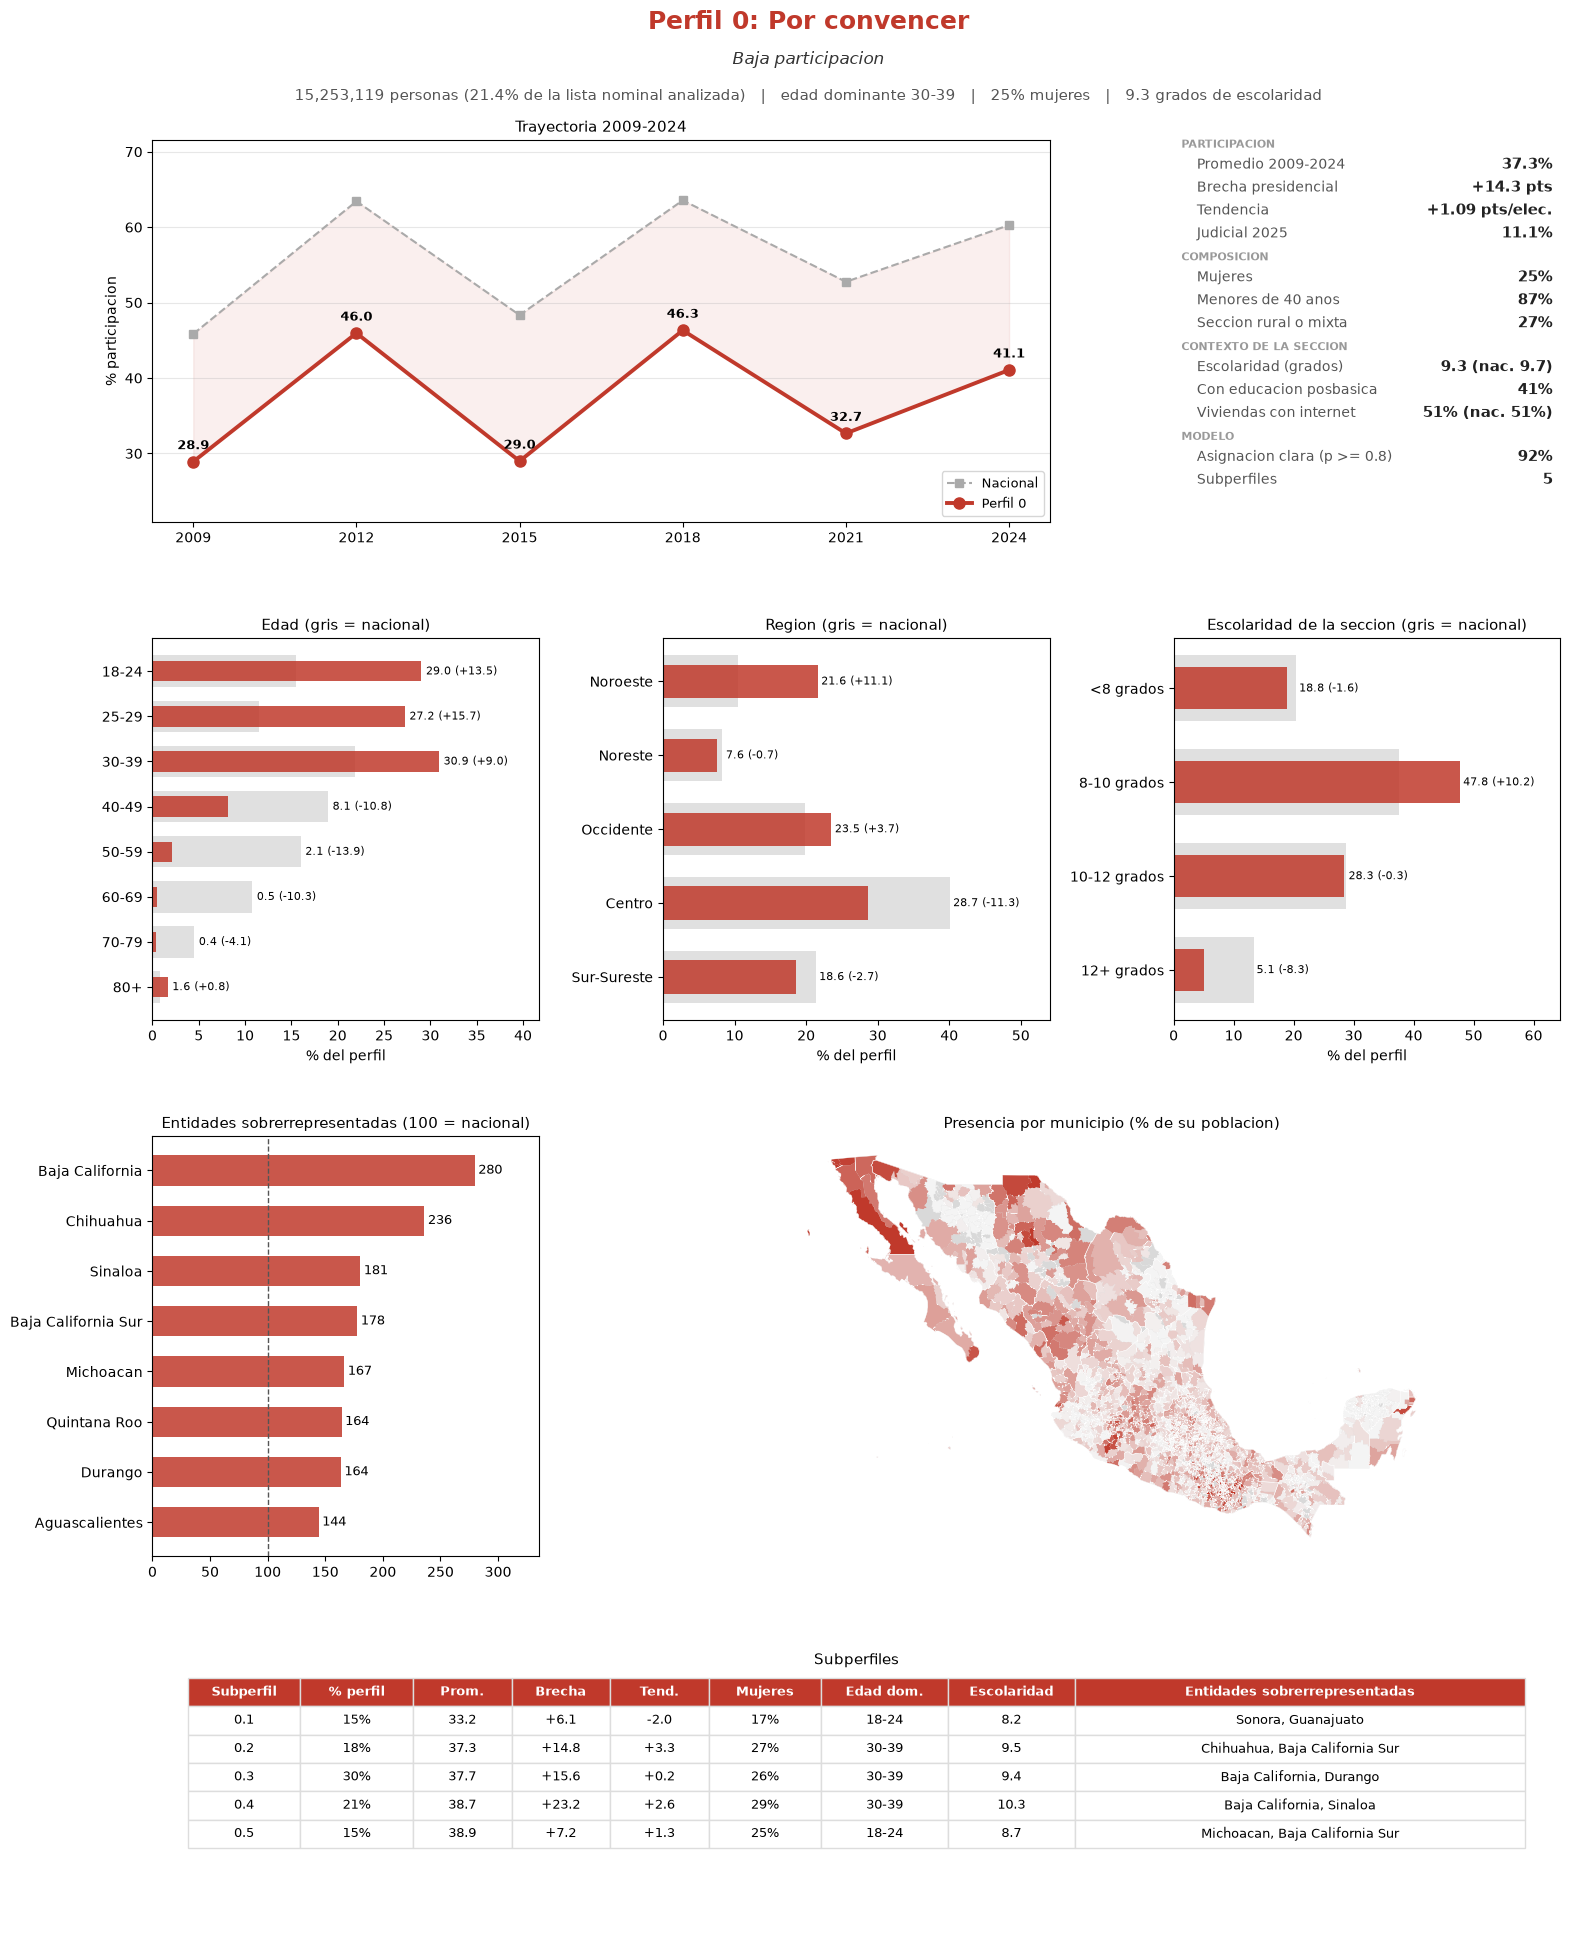

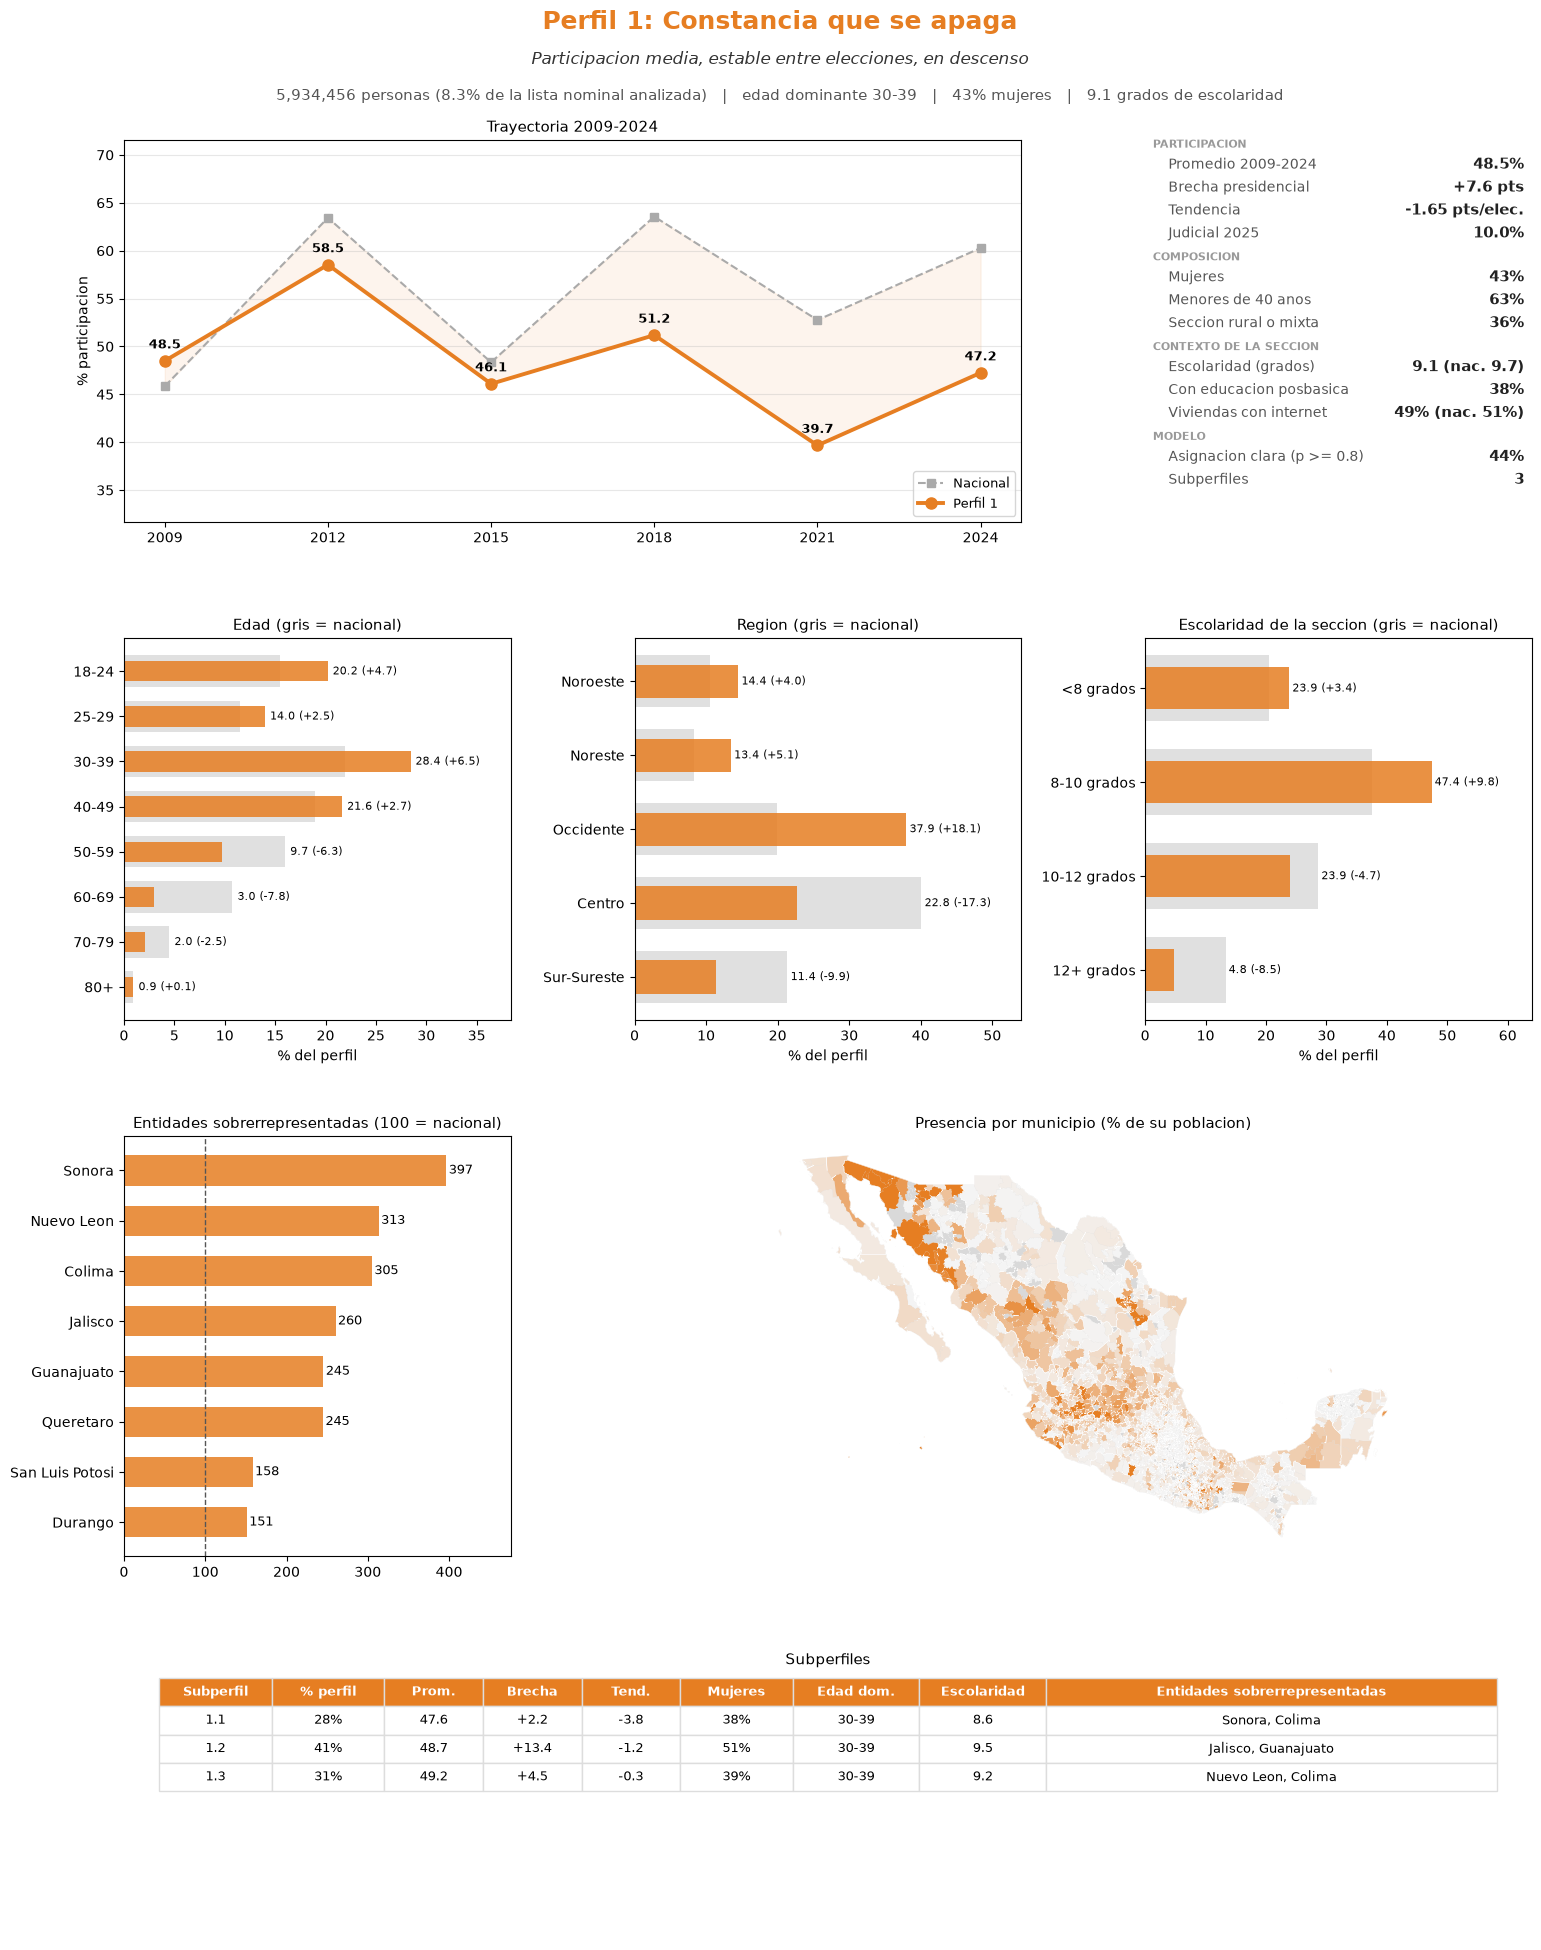

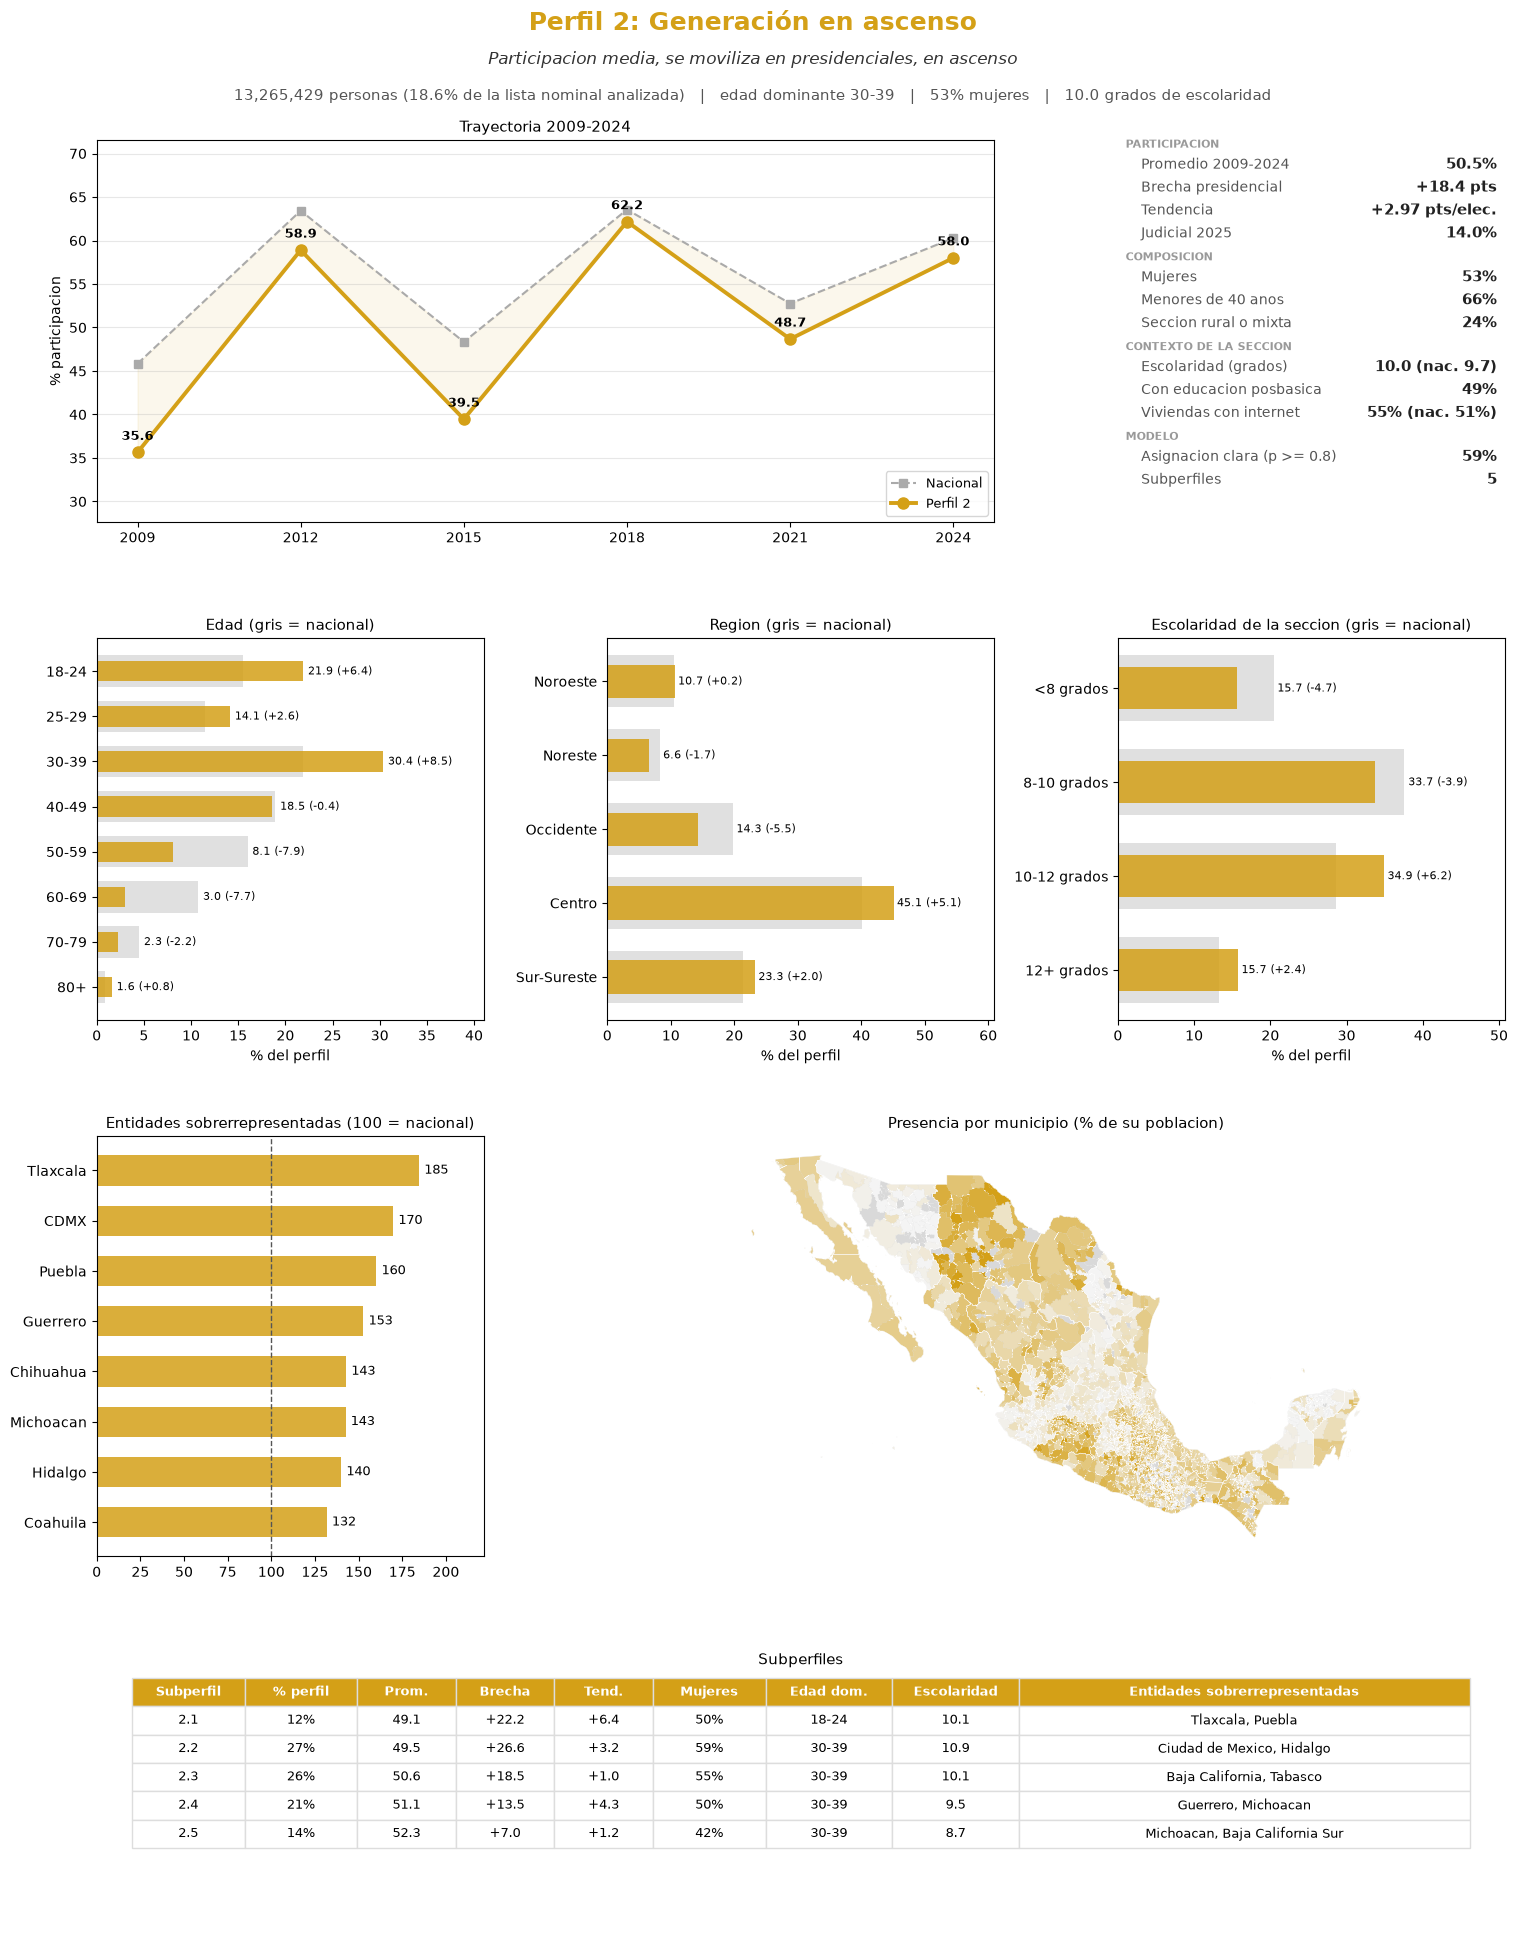

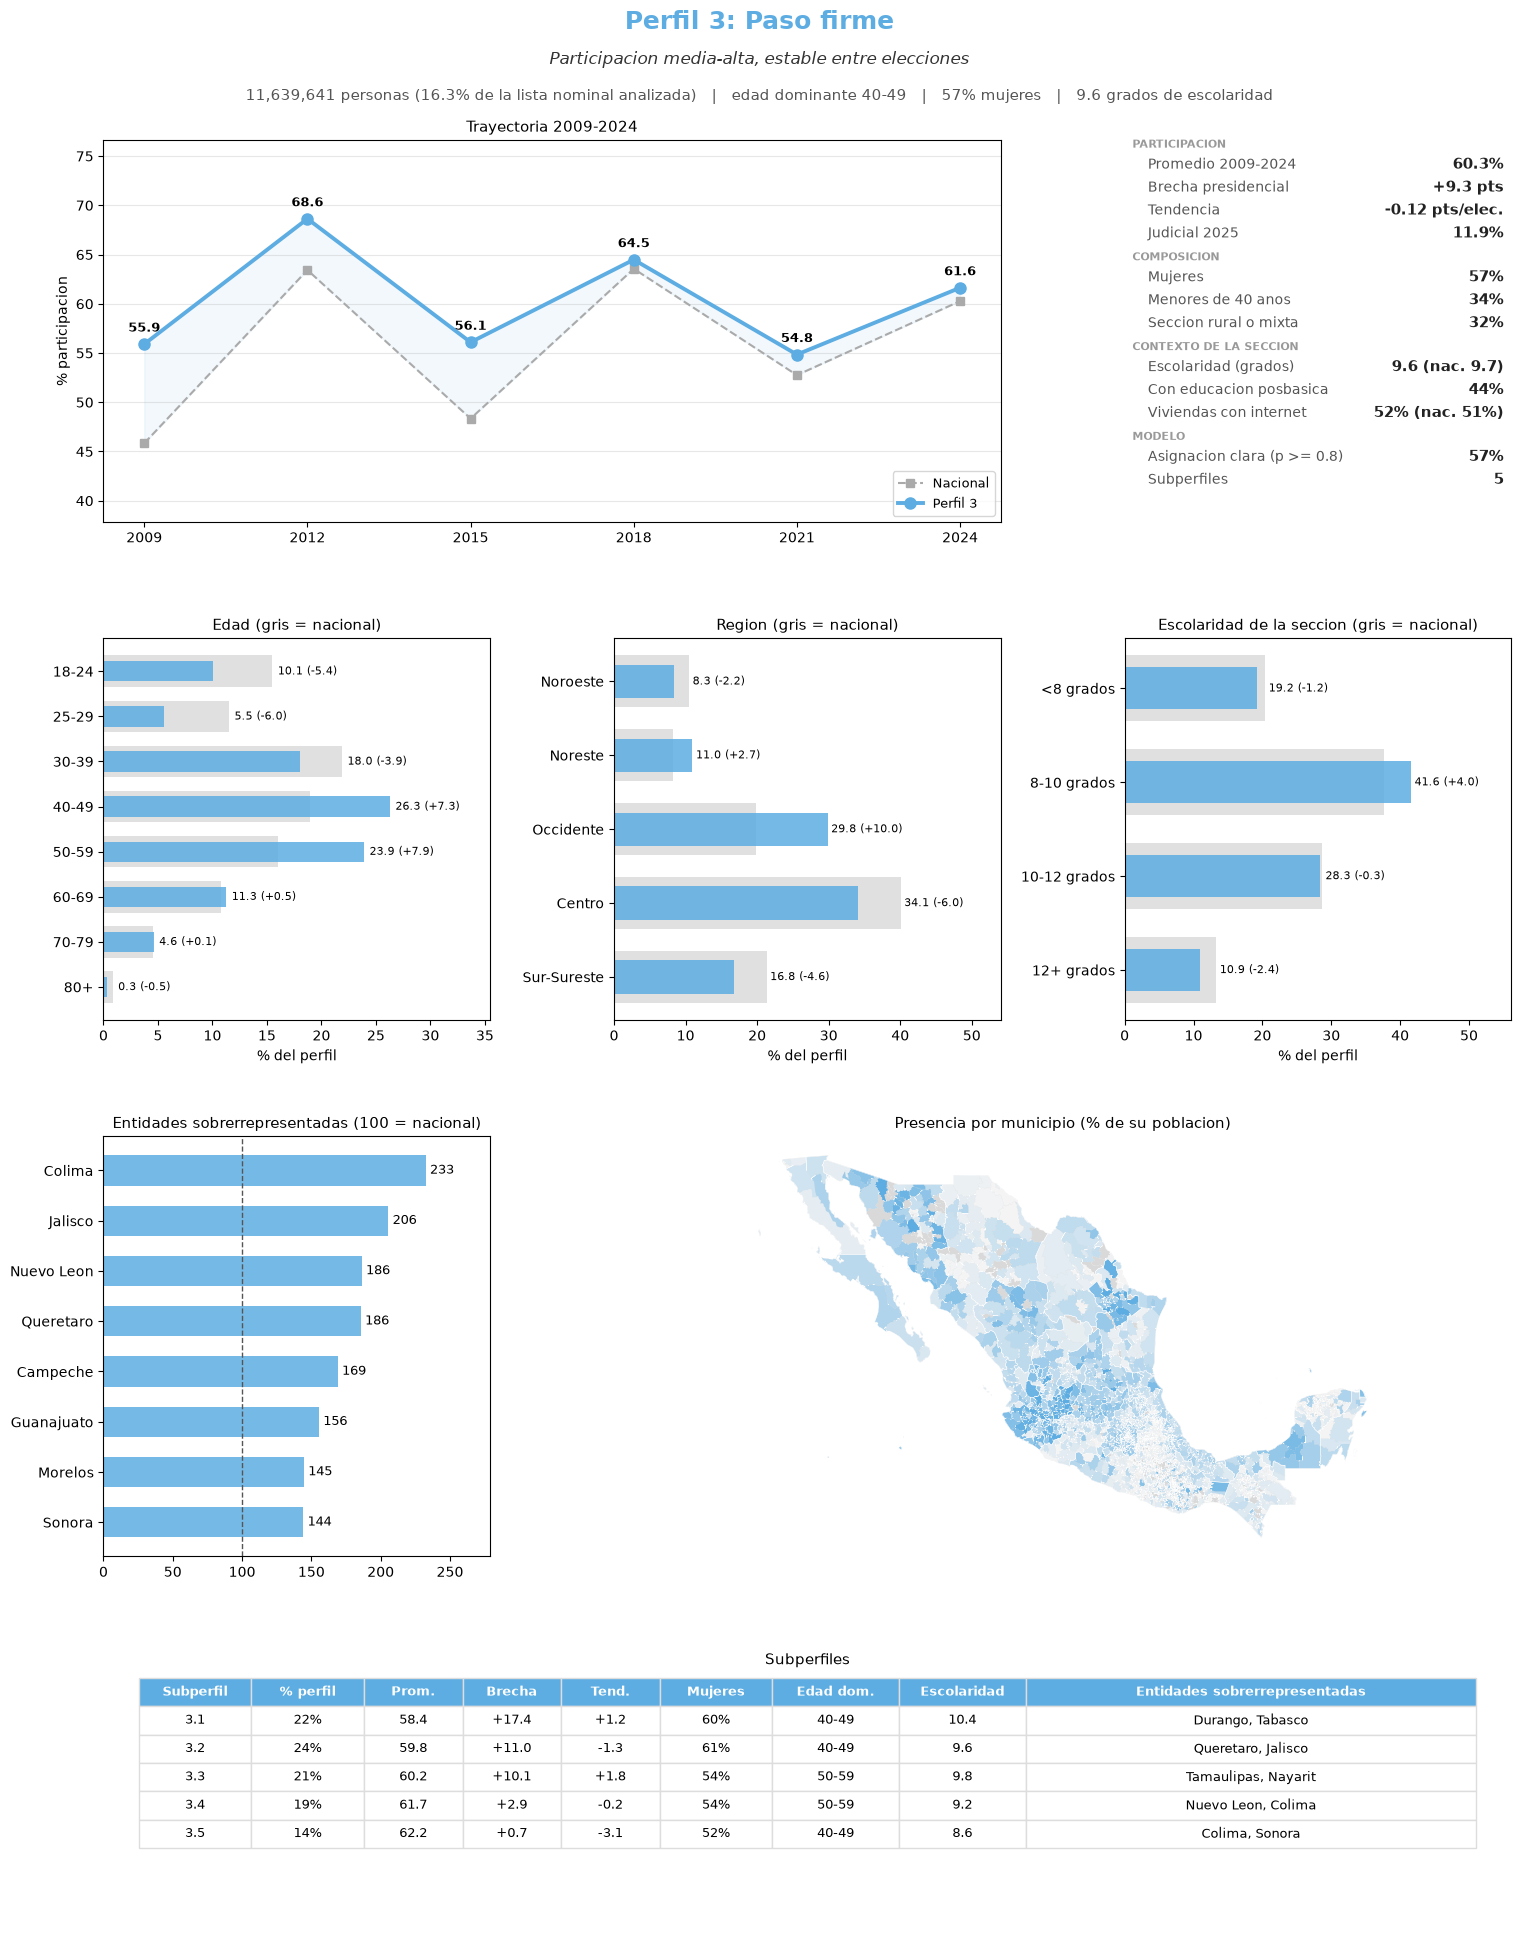

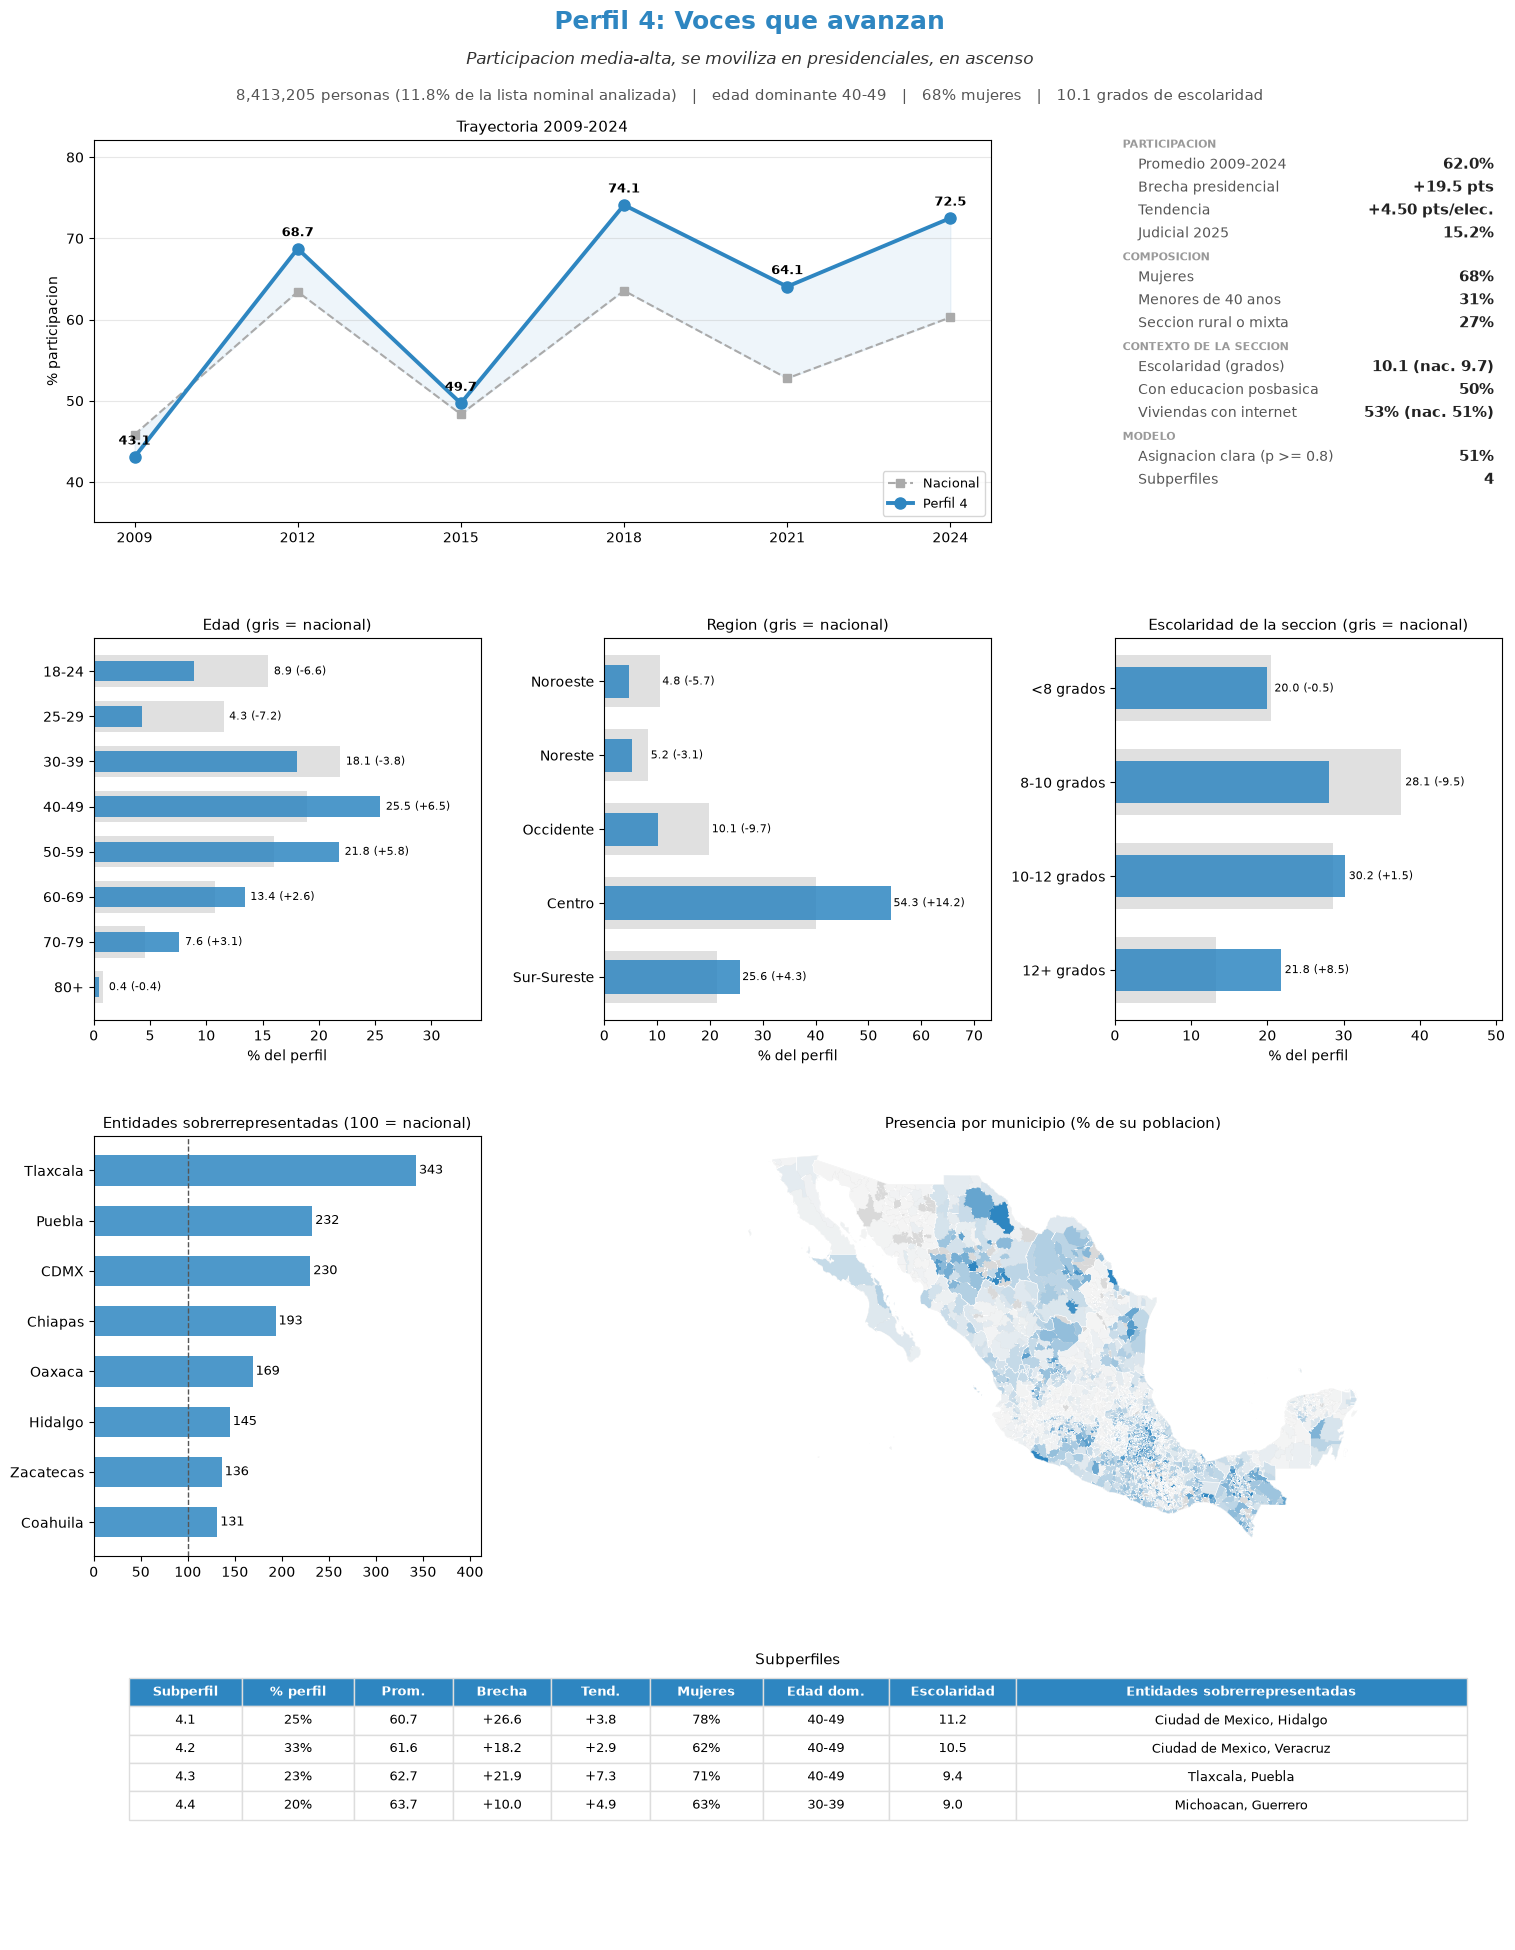

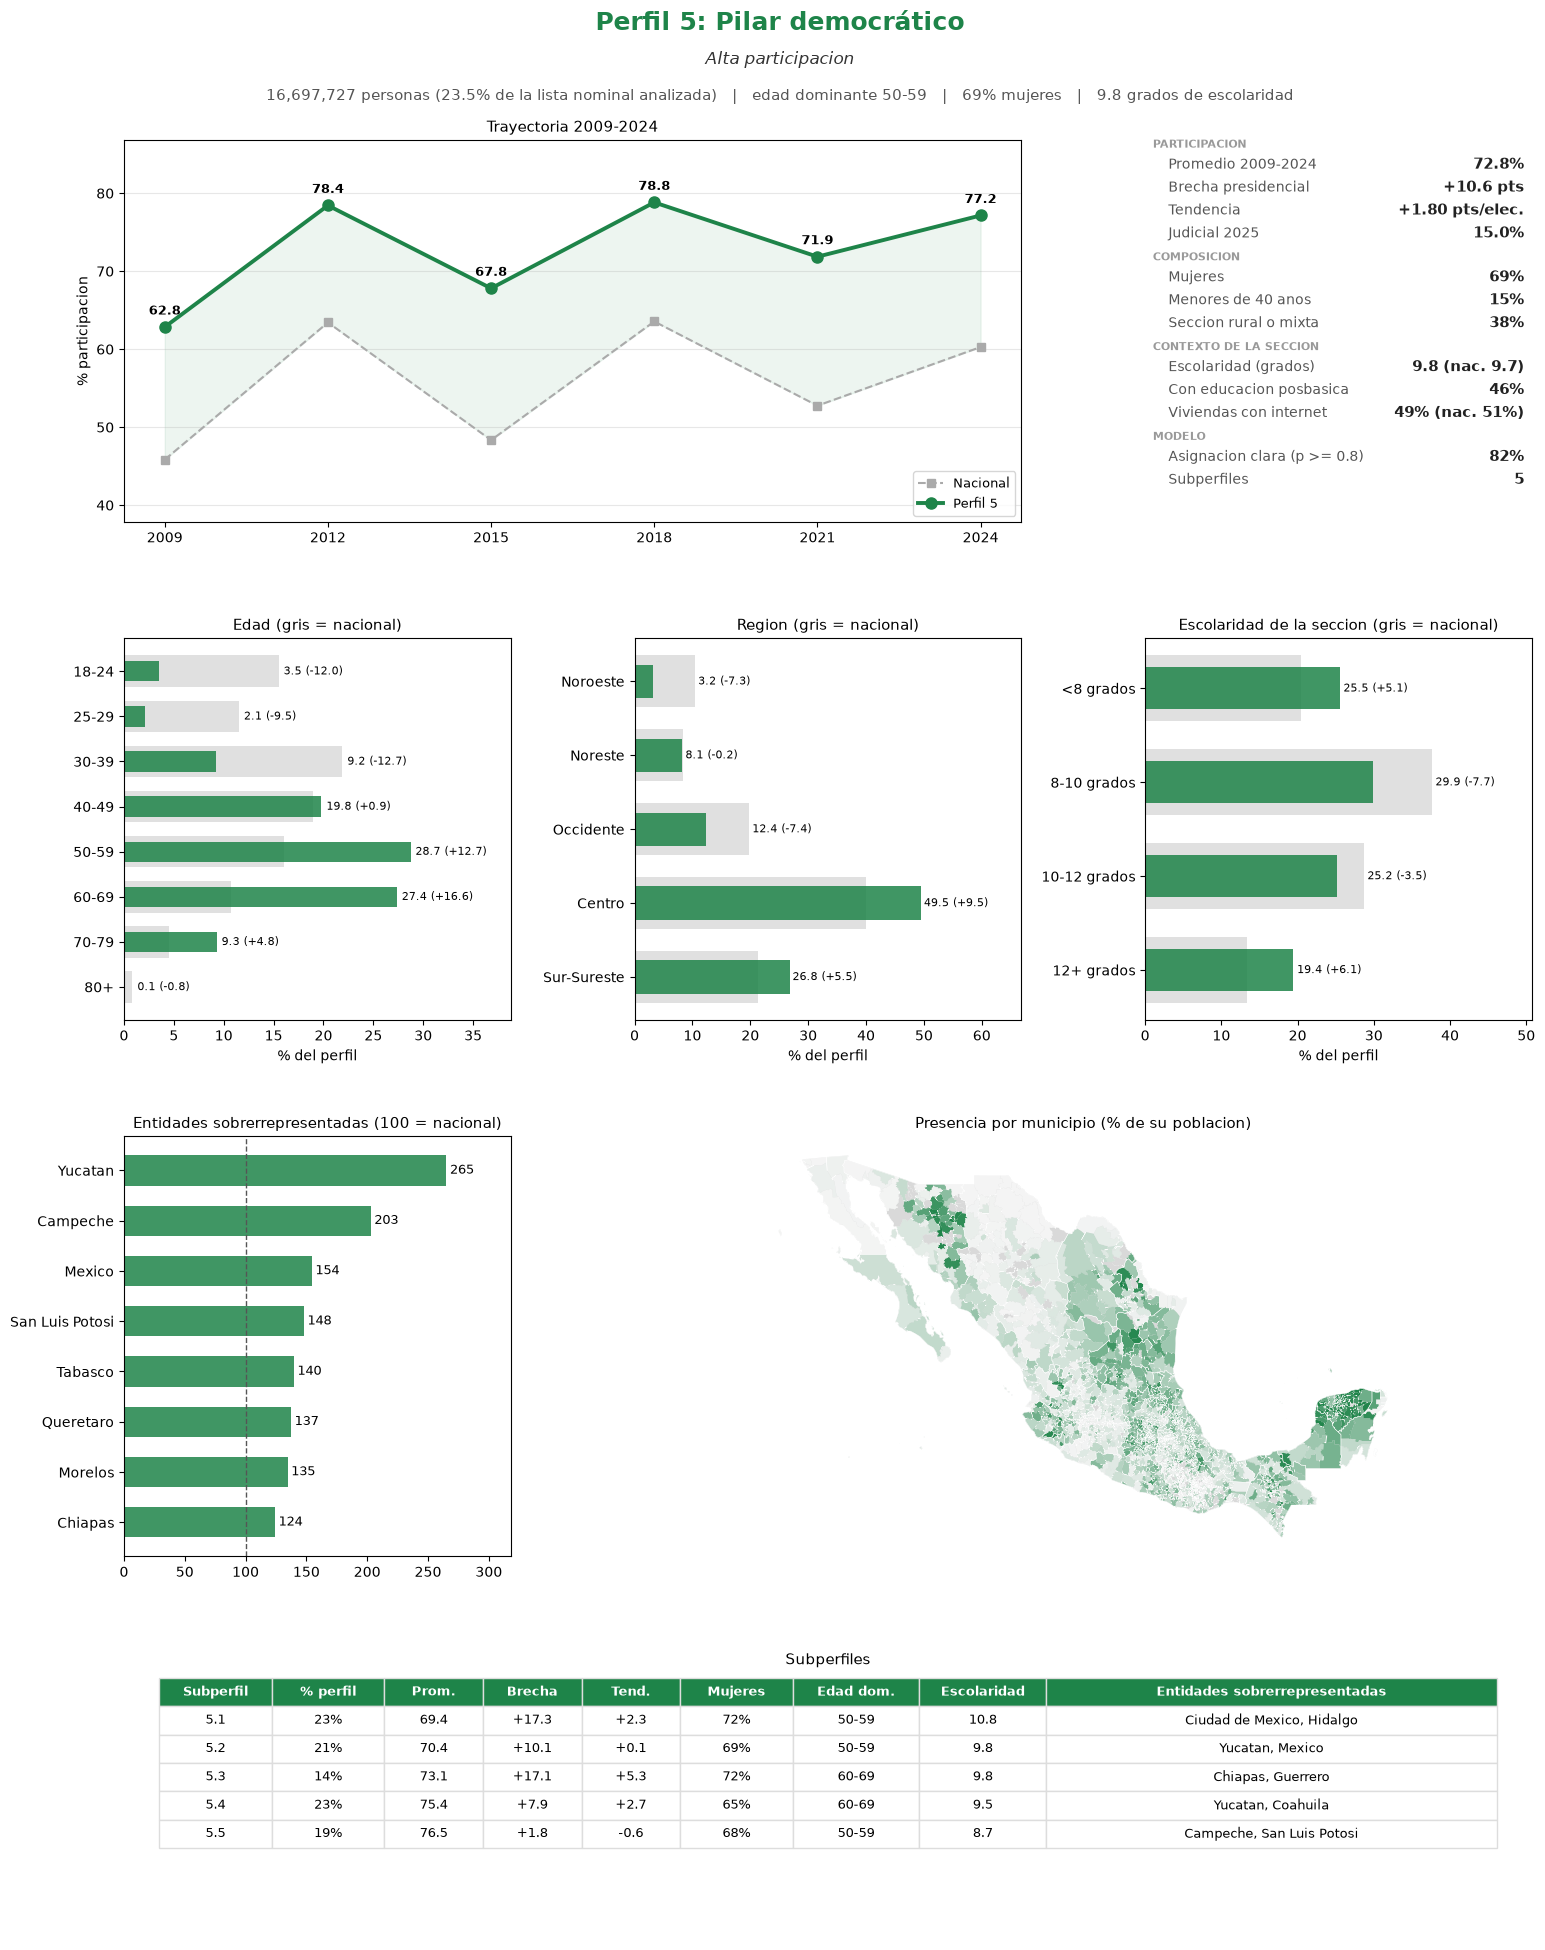

In [14]:
def barras_vs_nacional(ax, etiquetas, valores, nacional, color, titulo):
    yp = np.arange(len(etiquetas))
    ax.barh(yp, nacional, color="#e0e0e0", height=0.7)
    ax.barh(yp, valores, color=color, alpha=0.85, height=0.45)
    for i, (v, n) in enumerate(zip(valores, nacional)):
        ax.text(max(v, n) + 0.5, i, f"{v:.1f} ({v - n:+.1f})", va="center", fontsize=8)
    ax.set_yticks(yp, etiquetas)
    ax.invert_yaxis()
    ax.set_xlabel("% del perfil")
    ax.set_title(titulo, fontsize=11)
    ax.set_xlim(0, max(max(valores), max(nacional)) * 1.35)


def panel_metricas(ax, r, n_sub):
    ax.axis("off")
    items = [
        ("PARTICIPACION", None),
        ("Promedio 2009-2024", f"{r['promedio']:.1f}%"),
        ("Brecha presidencial", f"{r['brecha_pres']:+.1f} pts"),
        ("Tendencia", f"{r['tendencia']:+.2f} pts/elec."),
        ("Judicial 2025", f"{r['P_PJ2025']:.1f}%"),
        ("COMPOSICION", None),
        ("Mujeres", f"{r['MUJER']:.0f}%"),
        ("Menores de 40 anos", f"{r['MENOR_40']:.0f}%"),
        ("Seccion rural o mixta", f"{r['RURAL_MIXTA']:.0f}%"),
        ("CONTEXTO DE LA SECCION", None),
        ("Escolaridad (grados)", f"{r['escolaridad']:.1f} (nac. {nac_esc:.1f})"),
        ("Con educacion posbasica", f"{r['pct_posbasica']:.0f}%"),
        ("Viviendas con internet", f"{r['pct_internet']:.0f}% (nac. {nac_internet:.0f}%)"),
        ("MODELO", None),
        ("Asignacion clara (p >= 0.8)", f"{r['CLARA']:.0f}%"),
        ("Subperfiles", f"{n_sub}"),
    ]
    y = 0.98
    for etiqueta, valor in items:
        if valor is None:
            ax.text(0.02, y, etiqueta, transform=ax.transAxes, fontsize=8, fontweight="bold", color="#999")
            y -= 0.055
        else:
            ax.text(0.06, y, etiqueta, transform=ax.transAxes, fontsize=10, color="#555")
            ax.text(0.98, y, valor, transform=ax.transAxes, fontsize=11, fontweight="bold",
                    ha="right", color="#222")
            y -= 0.06


def tabla_subperfiles(ax, p, color):
    ax.axis("off")
    subs = res_sub.loc[p]
    filas = []
    for s, rs in subs.iterrows():
        top = ent_sub.loc[ent_sub["subperfil"] == s, "entidad"].head(2).tolist()
        filas.append([s, f"{rs['personas'] / subs['personas'].sum() * 100:.0f}%", f"{rs['promedio']:.1f}",
                      f"{rs['brecha_pres']:+.1f}", f"{rs['tendencia']:+.1f}", f"{rs['MUJER']:.0f}%",
                      rs["edad_dominante"], f"{rs['escolaridad']:.1f}", ", ".join(top)])
    tabla = ax.table(
        cellText=filas,
        colLabels=["Subperfil", "% perfil", "Prom.", "Brecha", "Tend.", "Mujeres", "Edad dom.",
                   "Escolaridad", "Entidades sobrerrepresentadas"],
        colWidths=[0.08, 0.08, 0.07, 0.07, 0.07, 0.08, 0.09, 0.09, 0.32],
        loc="upper center", cellLoc="center",
    )
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.scale(1, 1.7)
    for (i, _), celda in tabla.get_celld().items():
        celda.set_edgecolor("#ddd")
        if i == 0:
            celda.set_facecolor(color)
            celda.set_text_props(color="white", fontweight="bold")
    ax.set_title("Subperfiles", fontsize=11)


def ficha(p):
    r = res_perfil.loc[p]
    color = COLORES_PERFIL[p]
    dp = celdas[celdas["perfil"] == p]
    n_sub = res_sub.loc[p].shape[0]

    fig = plt.figure(figsize=(16, 20), facecolor="white")
    gs = fig.add_gridspec(4, 3, height_ratios=[1, 1, 1.1, 0.7], hspace=0.32, wspace=0.32,
                          top=0.92, bottom=0.02, left=0.09, right=0.97)
    fig.suptitle(f"Perfil {p}: {NOMBRES[p]}", fontsize=18, fontweight="bold", color=color, y=0.985)
    fig.text(0.5, 0.958, DESCRIPTORES[p], ha="center", fontsize=12, style="italic", color="#333")
    fig.text(0.5, 0.94, f"{r['personas']:,.0f} personas ({r['pct_pob']:.1f}% de la lista nominal analizada)"
             f"   |   edad dominante {r['edad_dominante']}   |   {r['MUJER']:.0f}% mujeres"
             f"   |   {r['escolaridad']:.1f} grados de escolaridad",
             ha="center", fontsize=11, color="#555")

    ax = fig.add_subplot(gs[0, :2])
    tray = tray_perfil.loc[p].to_numpy()
    ax.plot(ANOS, nac_tray, "s--", color="#aaa", linewidth=1.5, label="Nacional")
    ax.plot(ANOS, tray, "o-", color=color, linewidth=2.8, markersize=8, label=f"Perfil {p}")
    ax.fill_between(ANOS, tray, nac_tray, color=color, alpha=0.08)
    for a, v in zip(ANOS, tray):
        ax.annotate(f"{v:.1f}", (a, v), textcoords="offset points", xytext=(0, 9), ha="center",
                    fontsize=9, fontweight="bold")
    ax.set_xticks(ANOS)
    ax.set_ylabel("% participacion")
    ax.set_ylim(max(0, min(tray.min(), min(nac_tray)) - 8), min(100, max(tray.max(), max(nac_tray)) + 8))
    ax.set_title("Trayectoria 2009-2024", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower right", fontsize=9)

    panel_metricas(fig.add_subplot(gs[0, 2]), r, n_sub)

    edad = dp.groupby("GRUPO_EDAD")["peso"].sum().reindex(ETIQUETAS_EDAD, fill_value=0) / dp["peso"].sum() * 100
    barras_vs_nacional(fig.add_subplot(gs[1, 0]), ETIQUETAS_EDAD, edad.to_numpy(), nac_edad.to_numpy(),
                       color, "Edad (gris = nacional)")

    reg = dp.groupby("REGION")["peso"].sum().reindex(REGIONES_ORDEN, fill_value=0) / dp["peso"].sum() * 100
    barras_vs_nacional(fig.add_subplot(gs[1, 1]), REGIONES_ORDEN, reg.to_numpy(), nac_reg.to_numpy(),
                       color, "Region (gris = nacional)")

    esc = dp.groupby("tramo_esc")["peso"].sum().reindex(TRAMOS_ESC, fill_value=0)
    esc = esc / esc.sum() * 100
    barras_vs_nacional(fig.add_subplot(gs[1, 2]), [f"{t} grados" for t in TRAMOS_ESC], esc.to_numpy(),
                       nac_esc_tramo.to_numpy(), color, "Escolaridad de la seccion (gris = nacional)")

    ax = fig.add_subplot(gs[2, 1:])
    col = f"pct_{p}"
    cmap = LinearSegmentedColormap.from_list(f"p{p}", ["#f4f4f4", color])
    gmun.plot(ax=ax, color=COLOR_SIN_DATOS, linewidth=0)
    gmun[gmun["suficiente"]].plot(ax=ax, column=col, cmap=cmap, vmin=0,
                                  vmax=float(np.nanpercentile(gmun[col], 98)), linewidth=0)
    gdf_edo.boundary.plot(ax=ax, color="white", linewidth=0.3)
    ax.set_axis_off()
    ax.set_title("Presencia por municipio (% de su poblacion)", fontsize=11)

    ax = fig.add_subplot(gs[2, 0])
    top = ent_perfil[ent_perfil["perfil"] == p].head(8)
    yp = np.arange(len(top))
    ax.barh(yp, top["indice"], color=color, alpha=0.85, height=0.6)
    ax.axvline(100, color="#555", linestyle="--", linewidth=1)
    for i, v in enumerate(top["indice"]):
        ax.text(v + 3, i, f"{v:.0f}", va="center", fontsize=9)
    ax.set_yticks(yp, top["entidad"].replace({"Ciudad de Mexico": "CDMX"}))
    ax.invert_yaxis()
    ax.set_xlim(0, top["indice"].max() * 1.2)
    ax.set_title("Entidades sobrerrepresentadas (100 = nacional)", fontsize=11)

    tabla_subperfiles(fig.add_subplot(gs[3, :]), p, color)
    return fig


with PdfPages(DIR_FICHAS / "fichas_perfiles.pdf") as pdf:
    for p in range(K):
        fig = ficha(p)
        fig.savefig(DIR_FICHAS / f"ficha_perfil_{p}.png", dpi=DPI_FICHA)
        pdf.savefig(fig)
        plt.show()

## 9. Mapa interactivo

Dos capas (se alternan en la esquina superior derecha):
- **Municipios** (visible al abrir): color del perfil dominante, mas intenso cuanto mayor su
  porcentaje. Popup con la composicion por perfil y el subperfil dominante.
- **Entidades:** perfil dominante y composicion por entidad.

Panel desplegable abajo a la izquierda con la descripcion de los perfiles. El mapa no se
despliega en el notebook para no inflar su tamano; se abre desde
`DATA/PREPROCESSED/fichas/mapa_clases_latentes.html`.

In [15]:
def barras_html(r):
    html = '<table style="width:100%;border-collapse:collapse;margin-top:4px;">'
    for p in range(K):
        v = r.get(f"pct_{p}", 0) or 0
        c = COLORES_PERFIL[p]
        html += (
            f'<tr><td style="font-size:10px;width:24px;"><b style="color:{c};">P{p}</b></td>'
            f'<td><div style="background:{c};height:9px;width:{max(1, int(v * 1.4))}px;border-radius:2px;"></div></td>'
            f'<td style="font-size:10px;width:34px;text-align:right;">{v:.0f}%</td></tr>'
        )
    return html + "</table>"


def popup_municipio(r):
    if not r["suficiente"]:
        return (f'<div style="font-family:Arial;font-size:12px;"><b>{r["NOMGEO"]}</b><br>'
                f'<span style="color:#999;">Sin datos suficientes</span></div>')
    s = r["subperfil_dom"]
    return (
        f'<div style="font-family:Arial;font-size:12px;width:230px;">'
        f'<b style="font-size:13px;">{r["NOMGEO"]}</b><br>'
        f'<span style="color:#666;">{EDONOM[r["EDOCVE"]]}</span><br>'
        f'{r["personas"]:,.0f} personas | participacion media {r["promedio"]:.1f}%<br>'
        f'Escolaridad media {r["escolaridad"]:.1f} grados | {r["pct_internet"]:.0f}% viviendas con internet<br>'
        f'{barras_html(r)}'
        f'<div style="margin-top:4px;font-size:11px;">Subperfil dominante: <b>{s}</b> '
        f'({r["pct_subperfil_dom"]:.0f}%)</div></div>'
    )


def popup_entidad(r):
    return (
        f'<div style="font-family:Arial;font-size:12px;width:230px;">'
        f'<b style="font-size:13px;">{EDONOM[r["EDOCVE"]]}</b><br>'
        f'{r["personas"]:,.0f} personas | participacion media {r["promedio"]:.1f}%<br>'
        f'Escolaridad media {r["escolaridad"]:.1f} grados | {r["pct_internet"]:.0f}% viviendas con internet<br>'
        f'{barras_html(r)}</div>'
    )


def panel_html():
    html = (
        '<div style="position:fixed;bottom:20px;left:10px;z-index:1000;background:white;'
        'border-radius:8px;box-shadow:0 2px 8px rgba(0,0,0,.3);font-family:Arial;font-size:11px;'
        'max-height:70vh;width:310px;overflow-y:auto;">'
        '<details open><summary style="cursor:pointer;padding:10px 14px;font-weight:bold;font-size:13px;">'
        'Perfiles de participacion</summary><div style="padding:0 14px 10px 14px;">'
    )
    for p, r in res_perfil.iterrows():
        c = COLORES_PERFIL[p]
        html += (
            f'<div style="border-left:5px solid {c};padding-left:8px;margin-bottom:10px;">'
            f'<b style="color:{c};">P{p}</b> <b>{NOMBRES[p]}</b><br>'
            f'<i style="color:#444;">{DESCRIPTORES[p]}</i><br>'
            f'<span style="color:#666;">{r["personas"]:,.0f} personas ({r["pct_pob"]:.1f}%)</span><br>'
            f'Prom. <b>{r["promedio"]:.1f}%</b> | Brecha <b>{r["brecha_pres"]:+.1f}</b> | '
            f'Tend. <b>{r["tendencia"]:+.1f}</b><br>'
            f'{r["MUJER"]:.0f}% mujeres | edad dom. {r["edad_dominante"]} | '
            f'{r["RURAL_MIXTA"]:.0f}% rural o mixta<br>'
            f'Escolaridad {r["escolaridad"]:.1f} grados | {r["pct_posbasica"]:.0f}% posbasica | '
            f'{r["pct_internet"]:.0f}% con internet</div>'
        )
    html += (
        f'<span style="display:inline-block;width:10px;height:10px;background:{COLOR_SIN_DATOS};'
        f'border-radius:2px;margin-right:6px;"></span><span style="color:#999;">Sin datos suficientes</span>'
        '</div></details></div>'
    )
    return html

In [16]:
m = folium.Map(
    location=[23.6, -102.5], zoom_start=5,
    tiles="https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
    attr="&copy; OpenStreetMap contributors &copy; CARTO",
)

fg_mun = folium.FeatureGroup(name="Municipios", show=True)
for _, r in gmun.iterrows():
    if r["suficiente"]:
        estilo = {"fillColor": COLORES_PERFIL[int(r["perfil_dom"])], "color": "#666", "weight": 0.3,
                  "fillOpacity": 0.25 + 0.6 * r["pct_dom"] / 100}
    else:
        estilo = {"fillColor": COLOR_SIN_DATOS, "color": "#aaa", "weight": 0.3, "fillOpacity": 0.3}
    folium.GeoJson(
        r.geometry.__geo_interface__,
        style_function=lambda x, e=estilo: e,
        tooltip=r["NOMGEO"],
        popup=folium.Popup(popup_municipio(r), max_width=260),
    ).add_to(fg_mun)
fg_mun.add_to(m)

fg_edo = folium.FeatureGroup(name="Entidades", show=False)
for _, r in gedo.iterrows():
    estilo = {"fillColor": COLORES_PERFIL[int(r["perfil_dom"])], "color": "#333", "weight": 1.5,
              "fillOpacity": 0.45}
    folium.GeoJson(
        r.geometry.__geo_interface__,
        style_function=lambda x, e=estilo: e,
        tooltip=EDONOM[r["EDOCVE"]],
        popup=folium.Popup(popup_entidad(r), max_width=260),
    ).add_to(fg_edo)
fg_edo.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.get_root().html.add_child(folium.Element(panel_html()))

ruta_mapa = DIR_FICHAS / "mapa_clases_latentes.html"
m.save(str(ruta_mapa))
print(f"Mapa guardado: {ruta_mapa} ({ruta_mapa.stat().st_size / 1024 ** 2:.1f} MB)")

Mapa guardado: /Users/dabidurazo/Documents/Proyectos MCD/Hackatones/INE_HACKATHON/DATA/PREPROCESSED/fichas/mapa_clases_latentes.html (12.5 MB)


## 10. Exportacion de tablas

In [17]:
tabla_mun = gmun.drop(columns="geometry").loc[:, ["CVEGEO", "EDOCVE", "NOMGEO", "personas", "promedio",
                                                    "escolaridad", "pct_internet", "perfil_dom", "pct_dom", "subperfil_dom",
                                                    "pct_subperfil_dom", "suficiente"]
                                                   + [f"pct_{p}" for p in range(K)]]
salidas = {
    "fichas_resumen_perfiles.csv": res_perfil.assign(nombre=pd.Series(NOMBRES), descriptor=pd.Series(DESCRIPTORES)).round(2),
    "fichas_municipios.csv": tabla_mun.round(2),
    "fichas_cruce_municipios.csv": cruce.drop(columns="nom"),
}
for nombre, df in salidas.items():
    df.to_csv(DIR_FICHAS / nombre, index=nombre == "fichas_resumen_perfiles.csv")

for f in sorted(DIR_FICHAS.iterdir()):
    print(f"{f.name}: {f.stat().st_size / 1024:.0f} KB")

ficha_perfil_0.png: 839 KB
ficha_perfil_1.png: 807 KB
ficha_perfil_2.png: 861 KB
ficha_perfil_3.png: 835 KB
ficha_perfil_4.png: 821 KB
ficha_perfil_5.png: 838 KB
fichas_cruce_municipios.csv: 125 KB
fichas_municipios.csv: 246 KB
fichas_perfiles.pdf: 8065 KB
fichas_resumen_perfiles.csv: 1 KB
mapa_clases_latentes.html: 12822 KB
mapa_perfil_dominante.png: 1062 KB
vista_general.png: 391 KB
